In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
PROJECT_PATH = '/content/drive/MyDrive/project'

In [ ]:
import requests
from PIL import Image, ImageDraw, ImageFont
import os

# 下载中文字体（以思源黑体为例）
def download_chinese_font():
    font_url = "https://github.com/adobe-fonts/source-han-sans/raw/release/OTF/SimplifiedChinese/SourceHanSansSC-Regular.otf"
    font_path = "SourceHanSansSC-Regular.otf"

    if not os.path.exists(font_path):
        response = requests.get(font_url)
        with open(font_path, 'wb') as f:
            f.write(response.content)

    return font_path

# 使用下载的字体
font_path = download_chinese_font()
font = ImageFont.truetype(font_path, 40)

开始模型参数量分析...


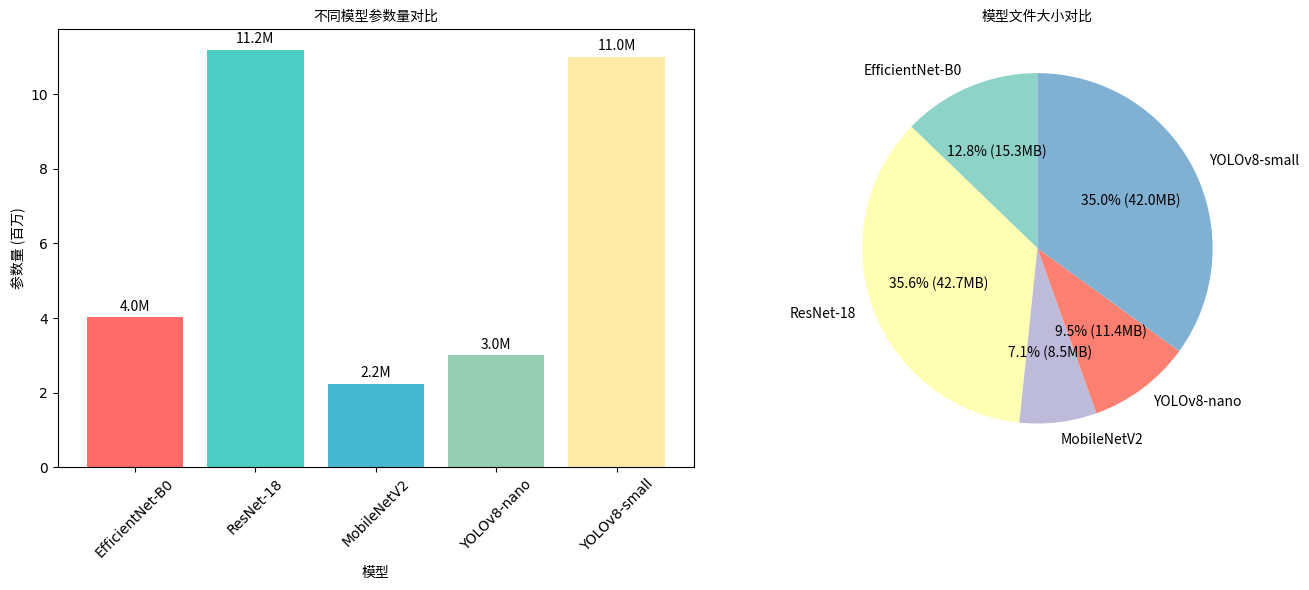

参数统计表:
          model  parameters   size_mb
EfficientNet-B0     4020358 15.336449
      ResNet-18    11181642 42.654579
    MobileNetV2     2236682  8.532265
    YOLOv8-nano     3000000 11.444092
   YOLOv8-small    11000000 41.961670


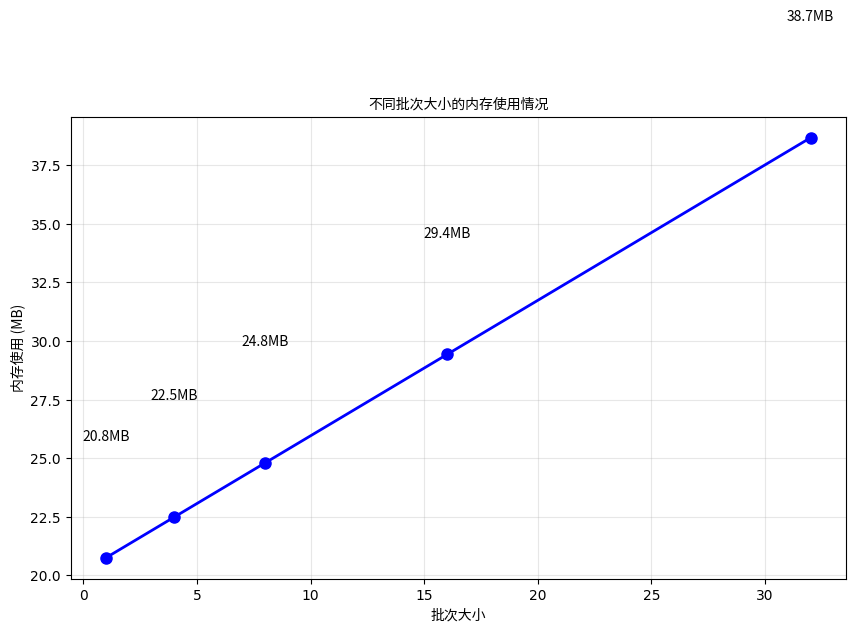

分析完成！图表已保存。


In [ ]:
import torch
import torch.nn as nn
from torchvision import models
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def calculate_model_parameters():
    """计算不同模型的参数量"""

    models_info = []

    # EfficientNet B0 (我们使用的模型)
    efficientnet = models.efficientnet_b0(weights=None)
    efficientnet.classifier[1] = nn.Linear(1280, 10)
    efficientnet_params = sum(p.numel() for p in efficientnet.parameters())
    models_info.append({
        'model': 'EfficientNet-B0',
        'parameters': efficientnet_params,
        'size_mb': efficientnet_params * 4 / (1024 ** 2)  # 4 bytes per float32
    })

    # ResNet18 (对比)
    resnet18 = models.resnet18(weights=None)
    resnet18.fc = nn.Linear(512, 10)
    resnet18_params = sum(p.numel() for p in resnet18.parameters())
    models_info.append({
        'model': 'ResNet-18',
        'parameters': resnet18_params,
        'size_mb': resnet18_params * 4 / (1024 ** 2)
    })

    # MobileNetV2 (对比)
    mobilenet = models.mobilenet_v2(weights=None)
    mobilenet.classifier[1] = nn.Linear(1280, 10)
    mobilenet_params = sum(p.numel() for p in mobilenet.parameters())
    models_info.append({
        'model': 'MobileNetV2',
        'parameters': mobilenet_params,
        'size_mb': mobilenet_params * 4 / (1024 ** 2)
    })

    # YOLOv8n (估算)
    yolo_params = 3000000  # 约3M参数 (YOLOv8n小型版本)
    models_info.append({
        'model': 'YOLOv8-nano',
        'parameters': yolo_params,
        'size_mb': yolo_params * 4 / (1024 ** 2)
    })

    # YOLOv8s (估算)
    yolo_params_s = 11000000  # 约11M参数
    models_info.append({
        'model': 'YOLOv8-small',
        'parameters': yolo_params_s,
        'size_mb': yolo_params_s * 4 / (1024 ** 2)
    })

    return pd.DataFrame(models_info)

def plot_parameters_comparison(df):
    """绘制参数量对比图"""

    # Create a FontProperties object for Matplotlib
    font_prop = fm.FontProperties(fname=font_path)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # 参数量条形图
    bars = ax1.bar(df['model'], df['parameters'] / 1e6, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7'])
    ax1.set_xlabel('模型', fontproperties=font_prop)
    ax1.set_ylabel('参数量 (百万)', fontproperties=font_prop)
    ax1.set_title('不同模型参数量对比', fontproperties=font_prop)
    ax1.tick_params(axis='x', rotation=45)

    # 在条形上添加数值标签
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                f'{height:.1f}M', ha='center', va='bottom', fontproperties=font_prop)

    # 模型大小饼图
    sizes = df['size_mb']
    labels = df['model']
    colors = plt.cm.Set3(range(len(labels)))

    def autopct_func(pct):
        return f'{pct:.1f}% ({pct*sum(sizes)/100:.1f}MB)'

    ax2.pie(sizes, labels=labels, colors=colors, autopct=autopct_func,
            startangle=90, textprops={'fontsize': 9, 'fontproperties': font_prop})
    ax2.set_title('模型文件大小对比', fontproperties=font_prop)

    plt.tight_layout()
    plt.savefig('model_parameters_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("参数统计表:") # Removed font=font as print does not support it directly
    print(df.to_string(index=False))

    return df

def analyze_memory_usage():
    """分析内存使用情况"""

    # Create a FontProperties object for Matplotlib
    font_prop = fm.FontProperties(fname=font_path)

    # 模拟不同批次大小的内存使用
    batch_sizes = [1, 4, 8, 16, 32]
    memory_usage = []

    for bs in batch_sizes:
        # 估算内存使用 (参数内存 + 激活值内存)
        # 假设输入尺寸为128x128 RGB图像
        input_size = bs * 3 * 128 * 128  # 输入像素数
        param_memory = 5288548 * 4 / (1024 ** 2)  # EfficientNet-B0参数量对应的内存

        # 估算激活值内存 (简化估算)
        # 第一层卷积输出: bs * 32 * 64 * 64
        conv1_activations = bs * 32 * 64 * 64 * 4 / (1024 ** 2)  # MB

        # 最后一层特征图: bs * 1280 * 4 * 4
        final_activations = bs * 1280 * 4 * 4 * 4 / (1024 ** 2)  # MB

        total_memory = param_memory + conv1_activations + final_activations
        memory_usage.append(total_memory)

    plt.figure(figsize=(10, 6))
    plt.plot(batch_sizes, memory_usage, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('批次大小', fontproperties=font_prop)
    plt.ylabel('内存使用 (MB)', fontproperties=font_prop)
    plt.title('不同批次大小的内存使用情况', fontproperties=font_prop)
    plt.grid(True, alpha=0.3)

    for i, (bs, mem) in enumerate(zip(batch_sizes, memory_usage)):
        plt.text(bs, mem + 5, f'{mem:.1f}MB', ha='center', fontproperties=font_prop)

    plt.savefig('memory_usage_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    print("开始模型参数量分析...")

    # 计算模型参数
    df = calculate_model_parameters()

    # 绘制对比图
    plot_parameters_comparison(df)

    # 分析内存使用
    analyze_memory_usage()

    print("分析完成！图表已保存。")